[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch22_LabCh22_Attention_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 22: Attention** (Part V: Attending).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=22](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=22)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch22 - Attention by Hand
## Scores, softmax, blends, masks, heads and the T² bill, computed by you and checked against Keras

This lab goes with **Chapter 22** of *The Why Book of Deep Learning*.

Attention is four lines of arithmetic: score every key against a query, divide by the square root of the key
size, turn the scores into weights with a softmax, and blend the values with those weights. In this lab you do
those four lines yourself on the chapter's tiny example ("the river bank": three tokens, two numbers each),
then catch `layers.MultiHeadAttention` doing exactly the same sums.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Compute scaled dot-product attention by hand: scores, weights, outputs | Steps 2 to 6 |
| Explain what dividing by √d_k does to the softmax as d grows | Steps 7 to 9 |
| Build a causal mask and a padding mask and see their effect | Steps 10 and 11 |
| Copy weights into `MultiHeadAttention` and reproduce your hand computation | Steps 12 to 14 |
| Predict the shapes and parameter count 4·(d² + d) of a multi-head layer | Steps 15 to 17 |
| Tell self-attention from cross-attention by its shapes | Step 18 |
| See that attention ignores order, and measure the T² cost | Steps 19 and 20 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** under a minute of computing on a laptop CPU, plus the time it takes to import TensorFlow
> (which can be a minute or two the first time). Nothing is trained and nothing is downloaded.

---
# Part A - Attention by hand on three tokens

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(22)
print("NumPy:", np.__version__)

NumPy: 2.4.6


---
## Step 2 - Three tokens, each with a query, a key and a value

The sentence is **"the river bank"**. In a real model each token's query, key and value come out of three
learnt `Dense` projections of its embedding (Part C does exactly that). Here we write them down directly,
two numbers each, so that every sum fits in your head.

* the **query** says what a token is looking for,
* the **key** says what a token offers to others,
* the **value** is what a token hands over if someone attends to it.

Read the two value numbers as "water-ness" and "money-ness". The static embedding of "bank" (Chapter 18)
sits at (1, 1): halfway between a riverside and a cash desk.

> **Predict:** looking only at the numbers, which token's key will match the query of "bank" best?

In [2]:
tokens = ["the", "river", "bank"]
Q = np.array([[0., 1.],     # the
              [1., 0.],     # river
              [2., 0.]])    # bank
K = np.array([[0., 0.],
              [2., 1.],
              [1., 1.]])
V = np.array([[0., 0.],
              [2., 0.],     # river: all water
              [1., 1.]])    # bank: half water, half money (the static vector)
d_k = Q.shape[1]
print("Q, K, V shapes:", Q.shape, K.shape, V.shape, "  (T = 3 tokens, d_k = 2)")

Q, K, V shapes: (3, 2) (3, 2) (3, 2)   (T = 3 tokens, d_k = 2)


---
## Step 3 - Score every key against every query

A score is a dot product: multiply the two vectors number by number and add. Doing it for every pair at once
is one matrix product, `Q @ K.T`, which gives a **T × T** table: row = the token asking, column = the token
being asked.

> **Predict:** the row for "bank". (Its query is (2, 0). Dot it with each of the three keys.)

In [3]:
def show(table, title, fmt="{:7.3f}"):
    print(title)
    print("          " + "".join(f"{t:>8s}" for t in tokens))
    for name, row in zip(tokens, table):
        print(f"{name:>8s}  " + "".join(fmt.format(v).rjust(8) for v in row))

scores = Q @ K.T
show(scores, "raw scores  Q @ K.T   (rows ask, columns answer)", "{:5.0f}")

raw scores  Q @ K.T   (rows ask, columns answer)
               the   river    bank
     the         0       1       1
   river         0       2       1
    bank         0       4       2


---
## Step 4 - Divide by √d_k

Here d_k = 2, so every score is divided by √2 ≈ 1.414. With two numbers per vector this changes little; Part B
shows why it matters enormously when vectors have 64 or 512 numbers.

> **Predict:** the largest scaled score in the table.

In [4]:
scaled = scores / np.sqrt(d_k)
show(scaled, f"scaled scores  (divided by sqrt({d_k}) = {np.sqrt(d_k):.3f})")

scaled scores  (divided by sqrt(2) = 1.414)
               the   river    bank
     the     0.000   0.707   0.707
   river     0.000   1.414   0.707
    bank     0.000   2.828   1.414


---
## Step 5 - Softmax each row into weights

Softmax raises *e* to the power of each score and divides by the row total, so every row becomes a set of
positive weights that **sum to 1**: a fixed budget of attention that the asking token must share out.
(Subtracting the row maximum first changes nothing mathematically and keeps `exp` from overflowing.)

> **Predict:** roughly what share of its attention "bank" gives to "river". More or less than half?

In [5]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

weights = softmax(scaled)
show(weights, "attention weights  softmax(scaled), row by row")
print("row sums:", weights.sum(axis=1))

attention weights  softmax(scaled), row by row
               the   river    bank
     the     0.198   0.401   0.401
   river     0.140   0.576   0.284
    bank     0.045   0.768   0.187
row sums: [1. 1. 1.]


---
## Step 6 - Blend the values

Each token's output is the weighted sum of **all** the values, using its own row of weights:
`output = weights @ V`, shape **(T, d_v)**.

> **Predict:** the new vector for "bank". Will its money-ness go up or down from the static 1.0?

In [6]:
out = weights @ V
for name, w, o in zip(tokens, weights, out):
    terms = " + ".join(f"{wi:.3f}*{tuple(int(x) for x in v)}" for wi, v in zip(w, V))
    print(f"{name:>6s}: {terms} = ({o[0]:.3f}, {o[1]:.3f})")
print("\nstatic 'bank' was (1, 1); contextual 'bank' is", out[2].round(3))

   the: 0.198*(0, 0) + 0.401*(2, 0) + 0.401*(1, 1) = (1.203, 0.401)
 river: 0.140*(0, 0) + 0.576*(2, 0) + 0.284*(1, 1) = (1.436, 0.284)
  bank: 0.045*(0, 0) + 0.768*(2, 0) + 0.187*(1, 1) = (1.723, 0.187)

static 'bank' was (1, 1); contextual 'bank' is [1.723 0.187]


### Why we see this

The query of "bank" lines up best with the key of "river" (score 4, scaled 2.828), so after the softmax
"river" gets about **77%** of the budget, "bank" itself about **19%**, and "the" under **5%**. The output is
therefore mostly river's value: **(1.723, 0.187)**. The same table row that said "bank: half water, half money"
has become "bank: mostly water". Nothing was looked up in a dictionary of senses; the neighbours rewrote the
vector. That is a **contextual embedding**, and it is what fixes the static "bank" of Chapter 18.

Notice also what did *not* happen: no weight is exactly 0. Attention is a **soft** lookup. Even "the" adds a
little of its value to everyone.

Let us wrap the four steps into one function, with an optional mask (used in Part C).

In [7]:
def attention(Q, K, V, mask=None):
    """Scaled dot-product attention. mask: 1 = may attend, 0 = may not (same shape as the score table)."""
    s = Q @ np.swapaxes(K, -1, -2) / np.sqrt(Q.shape[-1])
    if mask is not None:
        s = np.where(mask.astype(bool), s, -1e9)        # a huge negative number before the softmax
    w = softmax(s, axis=-1)
    return w @ V, w

o2, w2 = attention(Q, K, V)
print("same as the step-by-step result?", np.allclose(o2, out), np.allclose(w2, weights))

same as the step-by-step result? True True


---
# Part B - Why divide by √d_k?

---
## Step 7 - Dot products grow with the dimension

Take random queries and keys whose numbers have mean 0 and variance 1 (roughly what a well-initialised layer
produces). A dot product adds up d such products, so its spread grows like √d.

> **Predict:** the standard deviation of q·k when d = 512.

In [8]:
for d in (2, 16, 64, 512):
    q = rng.standard_normal((20000, d))
    k = rng.standard_normal((20000, d))
    dots = (q * k).sum(axis=1)
    print(f"d = {d:4d}: std of q.k = {dots.std():6.2f}   (sqrt(d) = {np.sqrt(d):6.2f})   "
          f"after dividing by sqrt(d): {(dots / np.sqrt(d)).std():.2f}")

d =    2: std of q.k =   1.42   (sqrt(d) =   1.41)   after dividing by sqrt(d): 1.00
d =   16: std of q.k =   4.02   (sqrt(d) =   4.00)   after dividing by sqrt(d): 1.01
d =   64: std of q.k =   7.95   (sqrt(d) =   8.00)   after dividing by sqrt(d): 0.99


d =  512: std of q.k =  22.62   (sqrt(d) =  22.63)   after dividing by sqrt(d): 1.00


---
## Step 8 - What big scores do to the softmax

One query against 10 random keys, repeated 2,000 times, with and without the division. We record the
**largest weight** in each row (1.0 means the softmax has become a hard, one-hot choice) and the size of the
softmax's gradient (the norm of its Jacobian, diag(p) − p pᵀ). A softmax that is nearly one-hot has a
gradient near zero: the scores can barely learn.

> **Predict:** at d = 512 without scaling, how often is the largest weight above 0.99?

In [9]:
def softmax_stats(d, scale, n_keys=10, trials=2000):
    q = rng.standard_normal((trials, 1, d))
    k = rng.standard_normal((trials, n_keys, d))
    s = (q @ np.swapaxes(k, 1, 2))[:, 0, :]
    if scale:
        s = s / np.sqrt(d)
    p = softmax(s)
    jac = np.einsum("ti,ij->tij", p, np.eye(n_keys)) - p[:, :, None] * p[:, None, :]
    return p.max(axis=1).mean(), (p.max(axis=1) > 0.99).mean(), np.linalg.norm(jac, axis=(1, 2)).mean()

dims = (2, 8, 32, 64, 128, 512)
stats = {}
print("   d | unscaled: mean max weight, share > 0.99, grad size | scaled: mean max weight, share > 0.99, grad size")
for d in dims:
    u, sc = softmax_stats(d, False), softmax_stats(d, True)
    stats[d] = (u, sc)
    print(f"{d:4d} |      {u[0]:.3f}        {u[1]:5.1%}      {u[2]:.3f}    |       {sc[0]:.3f}        {sc[1]:5.1%}      {sc[2]:.3f}")

   d | unscaled: mean max weight, share > 0.99, grad size | scaled: mean max weight, share > 0.99, grad size
   2 |      0.366         0.1%      0.339    |       0.293         0.0%      0.335
   8 |      0.616         2.1%      0.313    |       0.307         0.0%      0.344
  32 |      0.810        19.2%      0.206    |       0.319         0.0%      0.347
  64 |      0.869        34.8%      0.154    |       0.320         0.0%      0.346
 128 |      0.907        50.5%      0.116    |       0.319         0.0%      0.347


 512 |      0.950        71.3%      0.067    |       0.322         0.0%      0.347


### Why we see this

Without the division, the scores at d = 512 are spread over tens of units, so the largest one beats the rest by
a mile and the softmax hands it nearly all the weight: on average 0.95, and more than 0.99 in about seven rows
out of ten. The gradient through the softmax shrinks to about a fifth of its healthy size (0.067 against
0.347), and in the saturated rows it is close to zero: this is the same saturation that made sigmoid layers stop learning (Chapters 5 and 9).
Dividing by √d puts the scores back at a spread of about 1 at every width, so the weights stay soft and the
gradient stays alive. The scaling is not a tuning trick; it keeps the softmax in its working range whatever
size of head you choose.

---
## Step 9 - The same story as a picture

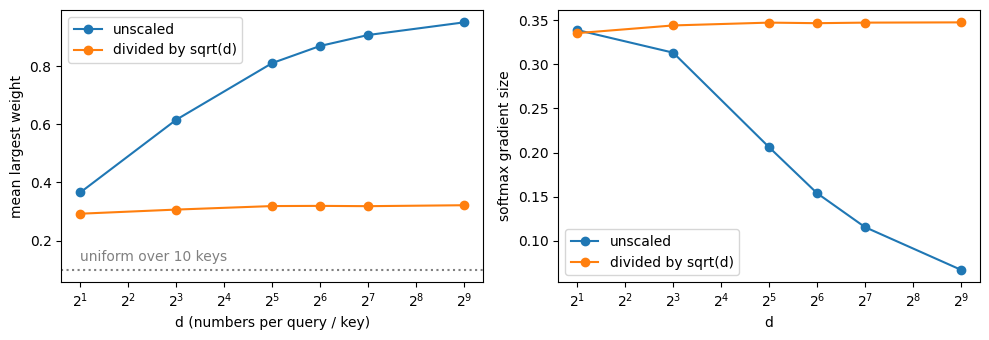

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(dims, [stats[d][0][0] for d in dims], "o-", label="unscaled")
ax[0].plot(dims, [stats[d][1][0] for d in dims], "o-", label="divided by sqrt(d)")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("d (numbers per query / key)"); ax[0].set_ylabel("mean largest weight")
ax[0].axhline(0.1, ls=":", c="grey"); ax[0].text(2, 0.13, "uniform over 10 keys", color="grey"); ax[0].legend()
ax[1].plot(dims, [stats[d][0][2] for d in dims], "o-", label="unscaled")
ax[1].plot(dims, [stats[d][1][2] for d in dims], "o-", label="divided by sqrt(d)")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("d"); ax[1].set_ylabel("softmax gradient size"); ax[1].legend()
plt.tight_layout(); plt.show()

---
# Part C - Masks: who may look at whom

---
## Step 10 - The causal mask

A model that writes text one token at a time must not peek at tokens it has not written yet. The causal
(look-ahead) mask is a lower triangle: token *i* may attend to tokens 0..*i* only. Masked scores are replaced
by a huge negative number before the softmax, so their weight comes out as 0.

> **Predict:** the first row of the masked weights ("the" may look only at itself), and whether the row for
> "bank" changes at all.

In [11]:
causal = np.tril(np.ones((3, 3)))
print("causal mask (1 = may look):\n", causal)
out_c, w_c = attention(Q, K, V, mask=causal)
show(w_c, "weights with the causal mask")
print("outputs:\n", out_c)

causal mask (1 = may look):
 [[1. 0. 0.]
 [1. 1. 0.]
 [1. 1. 1.]]
weights with the causal mask
               the   river    bank
     the     1.000   0.000   0.000
   river     0.196   0.804   0.000
    bank     0.045   0.768   0.187
outputs:
 [[0.    0.   ]
 [1.609 0.   ]
 [1.723 0.187]]


### Why we see this

"the" has nothing before it, so it puts all its weight on itself. "river" now shares its budget between "the"
and itself only: the weight that used to go to "bank" is redistributed, because every row must still sum to 1.
"bank" is the last token, it could already see everything, so its row is unchanged. During training the
whole sentence is processed at once, and the mask is what makes that honest.

---
## Step 11 - The padding mask

Sentences in a batch have different lengths, so short ones are padded to the longest with a pad token. The pad
positions are not words. If nothing stops it, every real token will spend some of its attention budget on them.

> **Predict:** for a 3-token sentence padded to length 5, what share of attention goes to the two pad
> positions without a mask?

In [12]:
pad_vec = np.array([[0.5, 0.5], [0.5, 0.5]])            # whatever vector the pad token happens to have
Qp, Kp, Vp = np.vstack([Q, pad_vec]), np.vstack([K, pad_vec]), np.vstack([V, pad_vec])
is_real = np.array([1, 1, 1, 0, 0])
pad_mask = np.ones((5, 1)) * is_real[None, :]             # every row may look only at real columns

_, w_nomask = attention(Qp, Kp, Vp)
out_m, w_mask = attention(Qp, Kp, Vp, mask=pad_mask)
print("share of attention on padding, no mask  :", w_nomask[:3, 3:].sum(axis=1).round(3))
print("share of attention on padding, with mask:", w_mask[:3, 3:].sum(axis=1).round(3))
print("real-token outputs with the mask equal the unpadded ones?", np.allclose(out_m[:3], out))

share of attention on padding, no mask  : [0.36  0.285 0.155]
share of attention on padding, with mask: [0. 0. 0.]
real-token outputs with the mask equal the unpadded ones? True


### Why we see this

Without the mask the pad positions take a real share of every row, and the outputs change depending on how much
padding a sentence happened to get in its batch. With the mask the real tokens give the padding exactly zero
and their outputs are identical to the unpadded sentence. (The rows *of* the pad positions are garbage either
way; the loss must ignore them too.)

---
# Part D - The same sums inside Keras

---
## Step 12 - Import TensorFlow and build a one-head layer

`layers.MultiHeadAttention(num_heads, key_dim)` contains four `Dense`-like projections: query, key, value and
output. To reproduce Part A exactly we feed it the three tokens as **one-hot** vectors (an identity matrix), so
that each projection simply looks up its own row: the query kernel *is* our Q table, and so on. We ask for a
2-number output with `output_shape=2` and will set that projection to the identity.

> **Predict:** the shapes of the eight weight arrays.

In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(22)
print("TensorFlow:", tf.__version__, "  Keras:", keras.__version__)

X = np.eye(3, dtype="float32")[None]                       # (batch 1, T 3, features 3): one-hot tokens
mha1 = layers.MultiHeadAttention(num_heads=1, key_dim=2, output_shape=2)
_ = mha1(X, X)                                              # call once so the weights exist
for w in mha1.weights:
    print(f"{w.path:55s} {tuple(w.shape)}")

TensorFlow: 2.21.0   Keras: 3.14.1
multi_head_attention/query/kernel                       (3, 1, 2)
multi_head_attention/query/bias                         (1, 2)
multi_head_attention/key/kernel                         (3, 1, 2)
multi_head_attention/key/bias                           (1, 2)
multi_head_attention/value/kernel                       (3, 1, 2)
multi_head_attention/value/bias                         (1, 2)
multi_head_attention/attention_output/kernel            (1, 2, 2)
multi_head_attention/attention_output/bias              (2,)


---
## Step 13 - Copy our numbers in and compare

Kernels are stored as (input features, heads, key_dim), so our 3 × 2 tables need a heads axis of size 1. All
biases are set to zero; the output kernel (heads, key_dim, output) is the 2 × 2 identity.

> **Predict:** the largest difference between Keras and Step 6.

In [14]:
zeros_b = np.zeros((1, 2), "float32")
mha1.set_weights([Q[:, None, :], zeros_b,                  # query kernel and bias
                  K[:, None, :], zeros_b,                  # key
                  V[:, None, :], zeros_b,                  # value
                  np.eye(2)[None], np.zeros(2)])           # output projection = identity
y, sc = mha1(X, X, return_attention_scores=True)
print("Keras output:\n", y.numpy()[0])
print("Keras attention weights (shape", tuple(sc.shape), "):\n", sc.numpy()[0, 0])
print("largest difference from the hand computation:",
      float(np.abs(y.numpy()[0] - out).max()), "and", float(np.abs(sc.numpy()[0, 0] - weights).max()))
assert np.allclose(y.numpy()[0], out, atol=1e-5) and np.allclose(sc.numpy()[0, 0], weights, atol=1e-5)

Keras output:
 [[1.203 0.401]
 [1.436 0.284]
 [1.723 0.187]]
Keras attention weights (shape (1, 1, 3, 3) ):
 [[0.198 0.401 0.401]
 [0.14  0.576 0.284]
 [0.045 0.768 0.187]]
largest difference from the hand computation: 4.269970044212812e-08 and 1.3270813559174144e-08


### Why we see this

The numbers agree to about a millionth, the size of float32 rounding. Keras divides the queries by √key_dim
before taking the dot products, which is the same thing as dividing the scores. What Keras calls
`attention_scores` are the weights *after* the softmax: each row sums to 1.

---
## Step 14 - The causal mask in Keras

`use_causal_mask=True` builds the triangle for you.

> **Predict:** should this match Step 10 exactly?

In [15]:
y_c, sc_c = mha1(X, X, use_causal_mask=True, return_attention_scores=True)
print("Keras causal weights:\n", sc_c.numpy()[0, 0])
print("matches Step 10?", np.allclose(sc_c.numpy()[0, 0], w_c, atol=1e-5), np.allclose(y_c.numpy()[0], out_c, atol=1e-5))

Keras causal weights:
 [[1.    0.    0.   ]
 [0.196 0.804 0.   ]
 [0.045 0.768 0.187]]
matches Step 10? True True


---
## Step 15 - A real-sized layer: shapes and the hand count

Width d = 8, two heads, so each head works on d / heads = 4 numbers: `key_dim=4`. A batch of 2 sequences of
5 tokens.

> **Predict:** the output shape, the shape of the attention scores, and the parameter count. The four
> projections are each d × d weights plus d biases: 4·(d² + d).

In [16]:
d, heads, T = 8, 2, 5
x = rng.standard_normal((2, T, d)).astype("float32")
mha = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads)
y, sc = mha(x, x, return_attention_scores=True)
print("input  :", x.shape, "  (batch, T, d)")
print("output :", tuple(y.shape), "  (batch, T, d)")
print("scores :", tuple(sc.shape), "  (batch, heads, T, T)")
hand = 4 * (d * d + d)
print("parameters:", mha.count_params(), "   hand count 4*(d*d + d) =", hand)
assert mha.count_params() == hand

input  : (2, 5, 8)   (batch, T, d)
output : (2, 5, 8)   (batch, T, d)
scores : (2, 2, 5, 5)   (batch, heads, T, T)
parameters: 288    hand count 4*(d*d + d) = 288


---
## Step 16 - The count at d = 512, and the `key_dim` trap

The original Transformer used d = 512 with 8 heads of 64. In Keras, `key_dim` is the size **per head**.
A common mistake is to pass the model width there.

> **Predict:** the parameter count with `key_dim=64`, then with `key_dim=512` by mistake.

In [17]:
probe = np.zeros((1, 4, 512), "float32")
right = layers.MultiHeadAttention(num_heads=8, key_dim=64); right(probe, probe)
wrong = layers.MultiHeadAttention(num_heads=8, key_dim=512); wrong(probe, probe)
print(f"num_heads=8, key_dim=64 : {right.count_params():>10,}   (4*(512*512 + 512) = {4 * (512**2 + 512):,})")
print(f"num_heads=8, key_dim=512: {wrong.count_params():>10,}   ({wrong.count_params() / right.count_params():.1f} times bigger)")
for h in (1, 2, 4, 8, 16):
    m = layers.MultiHeadAttention(num_heads=h, key_dim=512 // h); m(probe, probe)
    print(f"  heads = {h:2d}, key_dim = {512 // h:3d}: {m.count_params():,}")
assert right.count_params() == 1_050_624

num_heads=8, key_dim=64 :  1,050,624   (4*(512*512 + 512) = 1,050,624)
num_heads=8, key_dim=512:  8,401,408   (8.0 times bigger)
  heads =  1, key_dim = 512: 1,050,624
  heads =  2, key_dim = 256: 1,050,624


  heads =  4, key_dim = 128: 1,050,624


  heads =  8, key_dim =  64: 1,050,624


  heads = 16, key_dim =  32: 1,050,624


### Why we see this

With `key_dim = d / heads` the four projections are d × d whatever the number of heads, so the count is
1,050,624 for 1, 2, 4, 8 or 16 heads: splitting into heads is free in parameters. Neither count depends on the
sequence length (we used 4 tokens; 4,000 would give the same number). Passing the width as `key_dim` makes
every head full-width: nearly eight times the parameters and the work, and no error message.

---
## Step 17 - Multi-head attention by hand, with the layer's own weights

Pull the weights out of the d = 8 layer and redo its computation in NumPy: project, split into heads, attend in
each head separately, then mix the heads with the output projection.

> **Predict:** do you need anything beyond the `attention` function from Step 6?

In [18]:
Wq, bq, Wk, bk, Wv, bv, Wo, bo = mha.get_weights()
print("query kernel", Wq.shape, " output kernel", Wo.shape)
q_h = np.einsum("btd,dhk->bhtk", x, Wq) + bq[None, :, None, :]     # (batch, heads, T, key_dim)
k_h = np.einsum("btd,dhk->bhtk", x, Wk) + bk[None, :, None, :]
v_h = np.einsum("btd,dhk->bhtk", x, Wv) + bv[None, :, None, :]
o_h, w_h = attention(q_h, k_h, v_h)                                 # every head at once
y_hand = np.einsum("bhtk,hkd->btd", o_h, Wo) + bo                   # mix the heads back to width d
print("largest difference from Keras, outputs:", float(np.abs(y_hand - y.numpy()).max()),
      " weights:", float(np.abs(w_h - sc.numpy()).max()))
print("head 0 and head 1 weights for token 0:\n", w_h[0, 0, 0].round(3), "\n", w_h[0, 1, 0].round(3))

query kernel (8, 2, 4)  output kernel (2, 4, 8)
largest difference from Keras, outputs: 7.559585146754699e-08  weights: 3.9596216361292846e-08
head 0 and head 1 weights for token 0:
 [0.237 0.138 0.22  0.227 0.178] 
 [0.204 0.19  0.196 0.207 0.202]


### Why we see this

Nothing new was needed: multi-head attention is the same four steps run side by side on smaller slices,
followed by one more projection that mixes what the heads found. The two heads give token 0 different weight
rows from the same input, because each head has its own projections. That is the whole point of having several:
each can attend for a different reason.

---
## Step 18 - Self-attention vs cross-attention

In self-attention the queries, keys and values all come from one sequence. In cross-attention (an
encoder-decoder model, Chapter 21) the **queries come from the decoder** and the **keys and values come from the
encoder**. In Keras: `mha(query, value)` (the key defaults to the value).

> **Predict:** a decoder of 4 tokens attends to an encoder of 6. Output shape? Score shape?

In [19]:
dec = rng.standard_normal((1, 4, d)).astype("float32")
enc = rng.standard_normal((1, 6, d)).astype("float32")
cross = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads)
y_self, s_self = cross(dec, dec, return_attention_scores=True)
y_x, s_x = cross(dec, enc, return_attention_scores=True)
print("self-attention  on the decoder: output", tuple(y_self.shape), " scores", tuple(s_self.shape))
print("cross-attention dec -> enc    : output", tuple(y_x.shape), " scores", tuple(s_x.shape))

self-attention  on the decoder: output (1, 4, 8)  scores (1, 2, 4, 4)
cross-attention dec -> enc    : output (1, 4, 8)  scores (1, 2, 4, 6)


### Why we see this

The output always has one row per **query**, so it keeps the decoder's length (4). The score table is
queries × keys: 4 × 6, no longer square. This is Chapter 21's "let the decoder look back at every encoder state",
with no bottleneck vector in between.

A padding mask in Keras is passed as `attention_mask` with shape (batch, T_query, T_key), 1 = may attend:

In [20]:
Xp = np.vstack([np.eye(3), np.zeros((2, 3))]).astype("float32")[None]     # 3 real tokens + 2 pads
keep = np.ones((1, 5, 5), "float32") * np.array([1, 1, 1, 0, 0], "float32")
_, s_pad = mha1(Xp, Xp, attention_mask=keep, return_attention_scores=True)
print("weight on the pad columns, rows of the real tokens:\n", s_pad.numpy()[0, 0, :3, 3:])

weight on the pad columns, rows of the real tokens:
 [[0. 0.]
 [0. 0.]
 [0. 0.]]


---
# Part E - What attention cannot see, and what it costs

---
## Step 19 - Shuffle the words

> **Predict:** if we feed "bank river the" instead of "the river bank", what happens to the output vectors?

In [21]:
perm = [2, 1, 0]
out_shuffled, _ = attention(Q[perm], K[perm], V[perm])
print("outputs for the shuffled sentence:\n", out_shuffled)
print("same vectors as before, just reordered?", np.allclose(out_shuffled, out[perm]))

outputs for the shuffled sentence:
 [[1.723 0.187]
 [1.436 0.284]
 [1.203 0.401]]
same vectors as before, just reordered? True


### Why we see this

Every token gets exactly the same vector as before, only in the shuffled order. Attention treats its input as a
**set**: nothing in the four steps knows which position a token came from (the property is called
permutation-equivariance). "Dog bites man" and "man bites dog" would get identical sets of vectors. This is why
a transformer adds position information to every token before the first attention layer (Chapter 23).

---
## Step 20 - The T² bill

Time full attention (one head, d = 64) as the sequence grows, and count the entries of the score table.

> **Predict:** when T doubles, by how much do the time and the size of the score table grow?

In [22]:
def time_attention(T, d=64, repeats=3):
    q, k, v = (rng.standard_normal((T, d)).astype("float32") for _ in range(3))
    best = 1e9
    for _ in range(repeats):
        t0 = time.perf_counter(); attention(q, k, v); best = min(best, time.perf_counter() - t0)
    return best

prev = None
print("     T |  score entries | score table (float32) |  time   | x previous")
for T in (250, 500, 1000, 2000, 4000):
    t = time_attention(T)
    ratio = "" if prev is None else f"{t / prev:5.1f}x"
    print(f"{T:6d} | {T * T:14,} | {T * T * 4 / 1e6:15.1f} MB    | {t * 1000:6.1f} ms | {ratio}")
    prev = t
print(f"\nT = 100,000 would need {100_000**2:,} scores = {100_000**2 * 4 / 1e9:.0f} GB, per head, per layer")

     T |  score entries | score table (float32) |  time   | x previous
   250 |         62,500 |             0.2 MB    |    1.0 ms | 
   500 |        250,000 |             1.0 MB    |    4.6 ms |   4.6x
  1000 |      1,000,000 |             4.0 MB    |   16.1 ms |   3.5x


  2000 |      4,000,000 |            16.0 MB    |   64.9 ms |   4.0x


  4000 |     16,000,000 |            64.0 MB    |  263.8 ms |   4.1x

T = 100,000 would need 10,000,000,000 scores = 40 GB, per head, per layer


### Why we see this

Each doubling of T makes the score table exactly four times bigger, and the time grows by roughly four once T
is large enough for the T × T work to dominate (at small T, fixed overheads blur the ratio; your machine's
numbers will differ, the trend will not). Ten times longer means a hundred times more scores. Memory is usually
what breaks first: at 100,000 tokens one head's table would not fit on any GPU. Chapter 25 is about the ways
round this, from exact block-by-block computation (FlashAttention) to approximations.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: make the query of "bank" (0, 2) instead of (2, 0) | Which token wins its attention now? | |
| 2 | Step 2: double every number in Q (keep K and V) | Do the weights get sharper or softer? | |
| 3 | Step 4: forget to divide by √d_k | How much more weight goes to "river"? | |
| 4 | Step 8: use 100 keys instead of 10 | Does the unscaled softmax saturate earlier or later? | |
| 5 | Step 10: use an *upper* triangle by mistake | Which token can now see only itself? | |
| 6 | Step 11: make the pad vector (5, 0) instead of (0.5, 0.5), no mask | How much attention does padding steal? | |
| 7 | Step 15: `num_heads=4, key_dim=2` | Parameter count? | |
| 8 | Step 20: d = 256 instead of 64 | Does the doubling ratio change? | |

---
## Exercises

1. Give each token a fourth number (d_k = 3) chosen so that "bank" attends mostly to itself. Check by hand
   before running.
2. Write `attention_loop(Q, K, V)` with plain Python loops (no matrix products) and check it against `attention`.
   Then time both at T = 500. What does this tell you about why GPUs love attention?
3. Add a learnt "temperature": divide the scores by `tau` instead of √d_k. Plot the weights of "bank" for
   `tau` from 0.1 to 10. What happens at each end?
4. Build the causal mask *and* a padding mask together for a batch of two sentences of lengths 5 and 3, padded
   to 5. Pass it to `mha` and check that no real token attends to a pad or to the future.
5. Count the multiply-adds of one self-attention layer at d = 512, T = 1,000: the four projections
   (4·T·d²) and the two T × T products (2·T²·d). Which part dominates? At what T are they equal?
6. Show that cross-attention's parameter count does not depend on the encoder or decoder length.

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| The four steps | scores = Q Kᵀ; divide by √d_k; softmax each row; weights × V |
| Worked example, "bank" | scores (0, 4, 2); scaled (0, 2.828, 1.414); weights (0.045, 0.768, 0.187); output (1.723, 0.187) |
| Why √d_k | dot products of random vectors spread like √d; dividing keeps scores near spread 1 |
| Unscaled at large d | softmax nearly one-hot, gradient near zero |
| Masks | set masked scores to a huge negative number before softmax; weight becomes 0 |
| Causal mask | lower triangle: token i sees 0..i |
| Shapes (self) | in (batch, T, d) → scores (batch, heads, T, T) → out (batch, T, d) |
| Shapes (cross) | queries (batch, T_q, d), keys/values (batch, T_k, d) → scores (batch, heads, T_q, T_k) → out (batch, T_q, d) |
| Parameters | 4·(d² + d) with key_dim = d / heads; d = 512: 1,050,624; independent of T and of heads |
| Keras `key_dim` | per head, not the model width |
| Keras `attention_scores` | the weights after the softmax |
| Order | attention alone is order-blind (permutation-equivariant) |
| Cost | T² scores per head per layer; 2× longer = 4× more |